In [1]:
import numpy as np
import pandas as pd
# import matplotlib.pyplot as plt
import networkx as nx
from numba import njit
from tqdm import tqdm


# Simulation parameters
T = 0.001
ens_num = 500
n_sweeps = 50


# Load networks
cdata = np.genfromtxt("JCancer_483_0.09.csv", delimiter=",")
ndata = np.genfromtxt("JNormal_483_0.09.csv", delimiter=",")

cdata = np.asarray(cdata, dtype=np.float64)
ndata = np.asarray(ndata, dtype=np.float64)


# Convert networks to lists
G1 = nx.Graph(cdata)
G2 = nx.Graph(ndata)

list_edges_cancer = np.asarray(list(G1.edges()), dtype=np.int64)
list_edges_normal = np.asarray(list(G2.edges()), dtype=np.int64)


# Prepare network
def prepare_network(network, list_edges):

    n = len(network)

    neighbors = [set(np.flatnonzero(network[i] != 0).tolist()) - {i}for i in range(n)]

    common_flat = []
    offsets = [0]

    for i, j in list_edges:
        common = sorted(neighbors[i].intersection(neighbors[j]))
        common_flat.extend(common)
        offsets.append(len(common_flat))

    triangles = []

    for i in range(n):
        for j in neighbors[i]:
            if i < j:
                common = neighbors[i].intersection(neighbors[j])
                for k in common:
                    if j < k:
                        triangles.append((i, j, k))

    triangles = np.asarray(triangles, dtype=np.int64).reshape(-1, 3)

    denominator = 0.0

    for i, j, k in triangles:
        denominator += abs(network[i, j] * network[j, k] * network[k, i])

    return (np.asarray(offsets, dtype=np.int64),np.asarray(common_flat, dtype=np.int64),triangles,denominator)


offsets_c, common_c, triangles_c, denominator_c = prepare_network(cdata, list_edges_cancer)

offsets_n, common_n, triangles_n, denominator_n = prepare_network(ndata, list_edges_normal)


# Energy
@njit
def Energy(network, triangles, denominator):

    if denominator == 0:
        return np.nan

    e = 0.0

    for p in range(len(triangles)):
        i, j, k = triangles[p]
        e += network[i, j] * network[j, k] * network[k, i]

    return -e / denominator


# Order parameter q
@njit
def Q(network):

    n = len(network)
    q = 0.0
    w = 0.0

    for i in range(n):
        for j in range(n):
            if i == j or network[i, j] == 0:
                continue

            for k in range(j + 1, n):
                if k == i or network[i, k] == 0:
                    continue

                q += network[i, j] * network[i, k]
                w += abs(network[i, j] * network[i, k])

    if w == 0:
        return np.nan

    return q / w


# Monte Carlo simulation at fixed temperature
@njit
def run_one_ensemble(Network, list_edges, offsets, common_flat,triangles, denominator, T, n_sweeps):

    network = Network.copy()
    mncs = len(list_edges)

    if mncs == 0:
        return np.nan, np.nan

    for step in range(n_sweeps * mncs):

        edge_idx = np.random.randint(0, mncs)

        i = list_edges[edge_idx, 0]
        j = list_edges[edge_idx, 1]

        s = 0.0

        for p in range(offsets[edge_idx], offsets[edge_idx + 1]):
            k = common_flat[p]
            s += network[j, k] * network[k, i]

        delta_E = 2.0 * s * network[i, j]

        if delta_E <= 0:
            network[i, j] *= -1
            network[j, i] *= -1

        elif np.random.random() < np.exp(-delta_E / T):
            network[i, j] *= -1
            network[j, i] *= -1

    energy = Energy(network, triangles, denominator)
    q = Q(network)

    return energy, q


# Monte Carlo simulation for many realizations
def monte_carlo_simulation(Network, list_edges, offsets, common_flat,triangles, denominator, T, ens_num, n_sweeps):

    energy_ens = np.zeros(ens_num)
    q_ens = np.zeros(ens_num)

    for ens in tqdm(range(ens_num)):

        energy_ens[ens], q_ens[ens] = run_one_ensemble(Network, list_edges, offsets, common_flat,triangles, denominator, T, n_sweeps)

    return energy_ens, q_ens


# Run simulations
energy_cancer, q_cancer = monte_carlo_simulation(cdata, list_edges_cancer, offsets_c, common_c,triangles_c, denominator_c, T, ens_num, n_sweeps)

energy_normal, q_normal = monte_carlo_simulation(ndata, list_edges_normal, offsets_n, common_n,triangles_n, denominator_n, T, ens_num, n_sweeps)






100%|██████████| 500/500 [00:35<00:00, 13.99it/s]


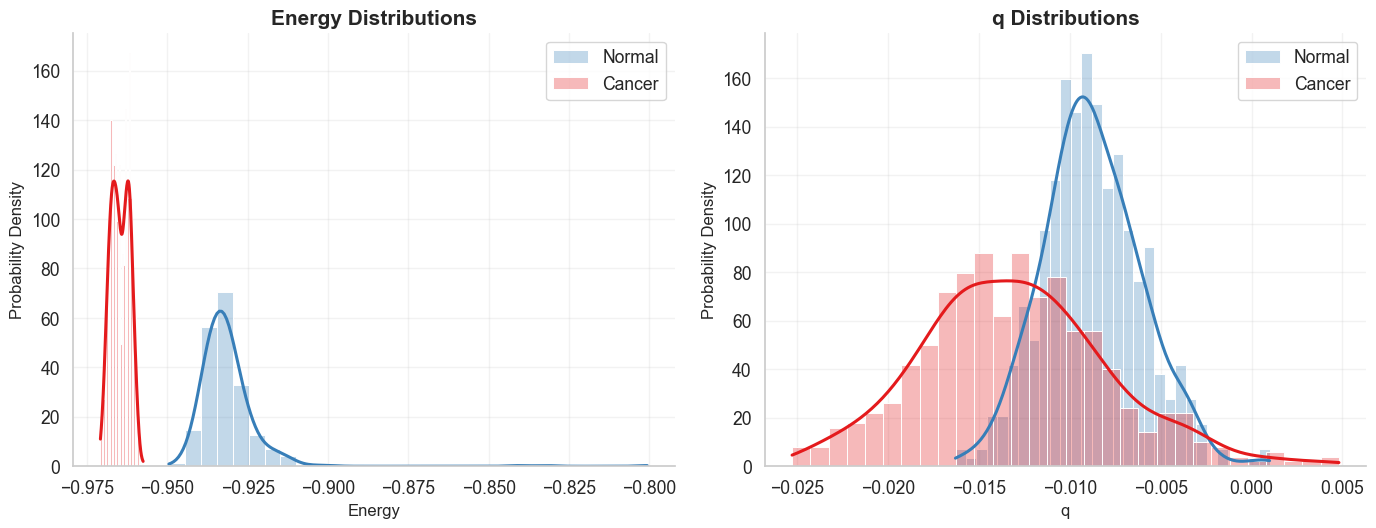

In [3]:
#Plot distributions
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.15)

energy_n = energy_normal[np.isfinite(energy_normal)]
energy_c = energy_cancer[np.isfinite(energy_cancer)]

q_n = q_normal[np.isfinite(q_normal)]
q_c = q_cancer[np.isfinite(q_cancer)]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

normal_color = "#377eb8"
cancer_color = "#e41a1c"

# Energy distributions
sns.histplot(energy_n,bins=30,stat="density",color=normal_color,alpha=0.30,edgecolor="white",linewidth=0.7,kde=True,line_kws={"linewidth": 2.2},ax=ax[0],label="Normal")
sns.histplot(energy_c,bins=30,stat="density",color=cancer_color,alpha=0.30,edgecolor="white",linewidth=0.7,kde=True,line_kws={"linewidth": 2.2},ax=ax[0],label="Cancer")

ax[0].set_title("Energy Distributions", fontsize=15, fontweight="bold")
ax[0].set_xlabel("Energy", fontsize=12)
ax[0].set_ylabel("Probability Density", fontsize=12)
ax[0].legend(frameon=True)
ax[0].grid(True, alpha=0.25)

# q distributions
sns.histplot(q_n,bins=30,stat="density",color=normal_color,alpha=0.30,edgecolor="white",linewidth=0.7,kde=True,line_kws={"linewidth": 2.2},ax=ax[1],label="Normal")
sns.histplot(q_c,bins=30,stat="density",color=cancer_color,alpha=0.30,edgecolor="white",linewidth=0.7,kde=True,line_kws={"linewidth": 2.2},ax=ax[1],label="Cancer")

ax[1].set_title("q Distributions", fontsize=15, fontweight="bold")
ax[1].set_xlabel("q", fontsize=12)
ax[1].set_ylabel("Probability Density", fontsize=12)
ax[1].legend(frameon=True)
ax[1].grid(True, alpha=0.25)

sns.despine()
plt.tight_layout()

# plt.savefig("Energy_q_distributions.png", dpi=300, bbox_inches="tight")
plt.show()